# 02 · Backtest design, baselines and features

Before any model is trained, this notebook sets up how every forecast is judged, and what "good" means. It covers:

1. How the backtest works (origins, horizons, and what the model may see)
2. The three baselines, scored on that backtest
3. Two example series with their baseline forecasts
4. The feature table the models will use, and how it is kept free of leakage

All scores are read from `reports/`, where `python -m forecast.backtest` writes them. Nothing here is typed in by hand.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from forecast import PROCESSED_DIR, REPO_ROOT
from forecast.backtest import add_week_index, make_origins
from forecast.features import (FEATURES, HORIZON_SALES_FEATURES, ID_FEATURES, KNOWN_FEATURES,
                               SALES_FEATURES, build_features, build_horizon_frame)
from forecast.plotting import (INK_SECONDARY, METHOD_COLORS, METHOD_LABELS, METHOD_MARKERS,
                               MUTED, GRID, SINGLE_COLOR, apply_style)

apply_style()
REPORTS = REPO_ROOT / "reports"
metrics = json.loads((REPORTS / "metrics.json").read_text())
board = pd.read_csv(REPORTS / "baseline_scoreboard.csv")
fc = pd.read_parquet(REPO_ROOT / "models" / "baseline_forecasts.parquet")
df = add_week_index(pd.read_parquet(PROCESSED_DIR / "tx_weekly.parquet"))
BASELINES = ["naive", "ma4", "snaive"]

## 1. How the backtest works

A forecast is made **at an origin week** (the last week whose sales we know) for **target weeks 1–4 weeks ahead** (horizon *h* = 1–4). The backtest repeats this at four origins, 4 weeks apart, at the end of the data. That gives four "what if we had forecast back then" exercises, whose target weeks together cover the last 16 weeks without overlap.

Rules (from CLAUDE.md):
- **Only time-based splits.** A random split would let the model learn from weeks after the ones it is tested on.
- **No leakage.** Sales features use only weeks up to and including the origin. Prices, SNAP days and events are known in advance, so the target week's values may be used.
- **Training rows must have their target at or before the origin.** For horizon *h*, a training row made at origin *o′* has its target at *o′ + h*. So only rows with *o′ ≤ o − h* are allowed. This is the easiest rule to get wrong; there is a test for it.

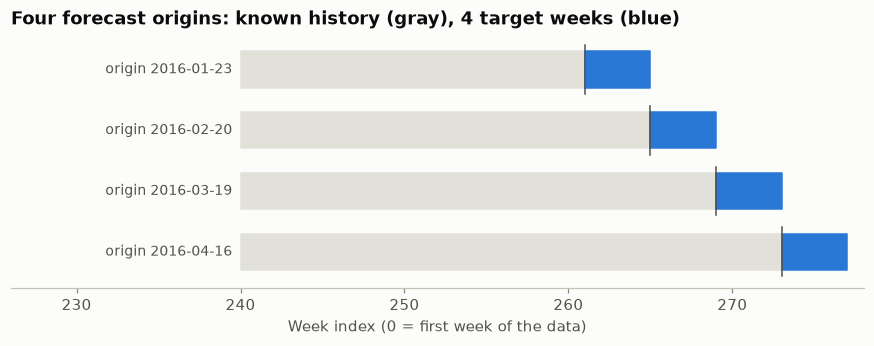

 origin_idx  wm_yr_wk week_start
        260     11552 2016-01-23
        264     11604 2016-02-20
        268     11608 2016-03-19
        272     11612 2016-04-16


In [2]:
origins = [o["origin_idx"] for o in metrics["origins"]]
start_of = dict(zip(df["week_idx"], df["week_start"]))
first_shown = origins[0] - 20

fig, ax = plt.subplots(figsize=(10, 3))
for row, o in enumerate(reversed(origins)):
    y = row
    ax.broken_barh([(first_shown, o - first_shown + 1)], (y - 0.3, 0.6), color=GRID)
    ax.broken_barh([(o + 1, 4)], (y - 0.3, 0.6), color=SINGLE_COLOR)
    ax.plot([o + 1, o + 1], [y - 0.4, y + 0.4], color=INK_SECONDARY, linewidth=1)
    ax.text(first_shown - 0.5, y, f"origin {start_of[o]:%Y-%m-%d}", ha="right", va="center",
            color=INK_SECONDARY, fontsize=9)
ax.set_yticks([])
ax.set_xlim(first_shown - 14, df["week_idx"].max() + 2)
ax.set_xlabel("Week index (0 = first week of the data)")
ax.set_title("Four forecast origins: known history (gray), 4 target weeks (blue)")
ax.grid(False)
for s in ("left",):
    ax.spines[s].set_visible(False)
plt.show()

print(pd.DataFrame(metrics["origins"]).to_string(index=False))

## 2. Baseline scoreboard

Three simple methods that every model must beat:
- **Naive:** next weeks look like last week.
- **4-week moving average:** the mean of the last 4 weeks.
- **Seasonal naive:** the same week last year. If a series did not exist then, it falls back to naive, so every method is scored on the same rows.

**Metrics:**
- **WAPE** = Σ|actual − forecast| / Σ actual. It measures the size of the errors relative to volume; lower is better.
- **Bias** = Σ(forecast − actual) / Σ actual. Positive means over-forecasting.

Both are reported at item-store-week level (the stocking decision) and at department-store-week level (planning totals). At department level, errors of different items partly cancel, so WAPE is lower. Bias does not change with level, because it is a ratio of sums either way.

In [3]:
overall = board[board["group_by"] == "overall"]
table = overall.pivot(index="method", columns="level", values=["wape", "bias"]).loc[BASELINES]
table.index = [METHOD_LABELS[m] for m in table.index]
print(f"Series: {metrics['n_series']:,} · forecast rows: {metrics['n_forecast_rows']:,} · "
      f"seasonal naive fell back to naive on {metrics['snaive_fallback_share']:.1%} of rows")
table.style.format("{:.3f}").set_caption("Baselines, all four origins pooled")

Series: 9,147 · forecast rows: 146,352 · seasonal naive fell back to naive on 0.7% of rows


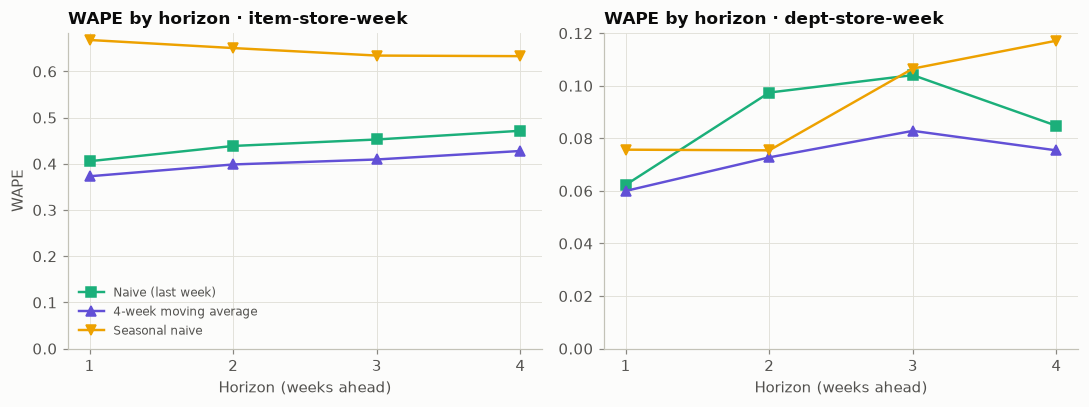

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, level in zip(axes, ["item-store-week", "dept-store-week"]):
    part = board[(board["group_by"] == "h") & (board["level"] == level)]
    for m in BASELINES:
        s = part[part["method"] == m].sort_values("group")
        ax.plot(s["group"].astype(int), s["wape"], color=METHOD_COLORS[m],
                marker=METHOD_MARKERS[m], markersize=7, label=METHOD_LABELS[m])
    ax.set_title(f"WAPE by horizon · {level}", fontsize=11)
    ax.set_xlabel("Horizon (weeks ahead)")
    ax.set_xticks([1, 2, 3, 4])
    ax.set_ylim(bottom=0)
axes[0].set_ylabel("WAPE")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

by_h = board[board["group_by"] == "h"].pivot_table(index=["level", "group"], columns="method", values="wape")[BASELINES]
by_h.style.format("{:.3f}").set_caption("WAPE by horizon (table view of the charts)")

**Reading it:**
- At item level, errors grow steadily the further ahead we forecast, as expected. At department level the pattern is bumpier. Each point there averages only 4 origins × 7 departments × 3 stores, so a single unusual week can move it; don't read much into one horizon.
- The 4-week moving average is the strongest baseline at both levels and every horizon: averaging four weeks smooths out a single unusual week.
- Seasonal naive is poor at item level, because a single item's sales in one week a year ago are noisy. At department level that noise averages out, and it is close to the others.
- **The baseline to beat is the 4-week moving average.**

### By demand type

Each series gets a Syntetos–Boylan class from its history up to the first origin:
- **ADI** is the average number of weeks between sales.
- **CV²** is how much the size of non-zero weeks varies.

| | steady size (CV² < 0.49) | varying size |
|---|---|---|
| **sells most weeks (ADI < 1.32)** | smooth | erratic |
| **many zero weeks** | intermittent | lumpy |

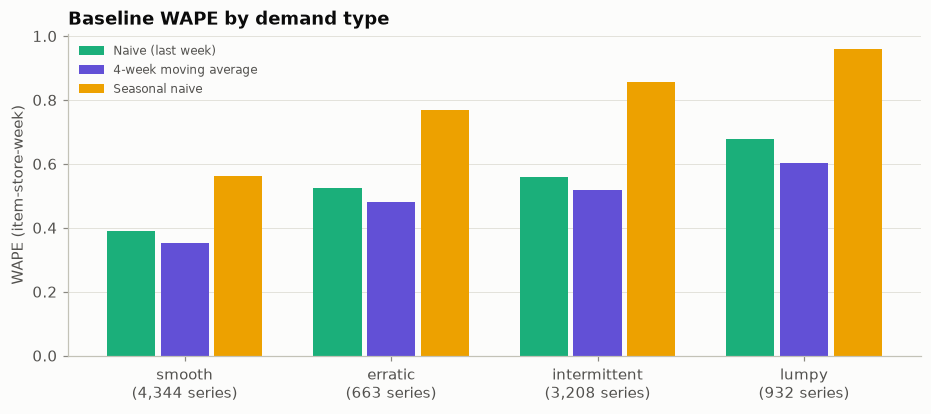

method,naive,ma4,snaive
group,,,
smooth,0.389,0.352,0.561
erratic,0.525,0.482,0.767
intermittent,0.559,0.520,0.857
lumpy,0.678,0.603,0.959


In [5]:
order = ["smooth", "erratic", "intermittent", "lumpy"]
part = board[(board["group_by"] == "demand_type")].pivot(index="group", columns="method", values="wape").loc[order, BASELINES]

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(order))
width = 0.26
for i, m in enumerate(BASELINES):
    ax.bar(x + (i - 1) * width, part[m], width * 0.9, color=METHOD_COLORS[m], label=METHOD_LABELS[m])
counts = metrics["demand_type_counts"]
ax.set_xticks(x, [f"{t}\n({counts[t]:,} series)" for t in order])
ax.set_ylabel("WAPE (item-store-week)")
ax.set_title("Baseline WAPE by demand type")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", fontsize=8)
plt.show()

part.style.format("{:.3f}").set_caption("WAPE by demand type (table view)")

**Reading it:** smooth series are the easiest and lumpy series the hardest, for every method. Intermittent and lumpy series together are a large share of the series, but a smaller share of the units, so they weigh less in the overall WAPE. This is why results are reported per demand type: a model can improve the totals while doing nothing for the hard series, or the reverse.

## 3. Two example series

To make the numbers concrete: the median-volume smooth series and the median-volume intermittent series, with each baseline's forecasts at every origin (horizons 1–4) against what actually sold.

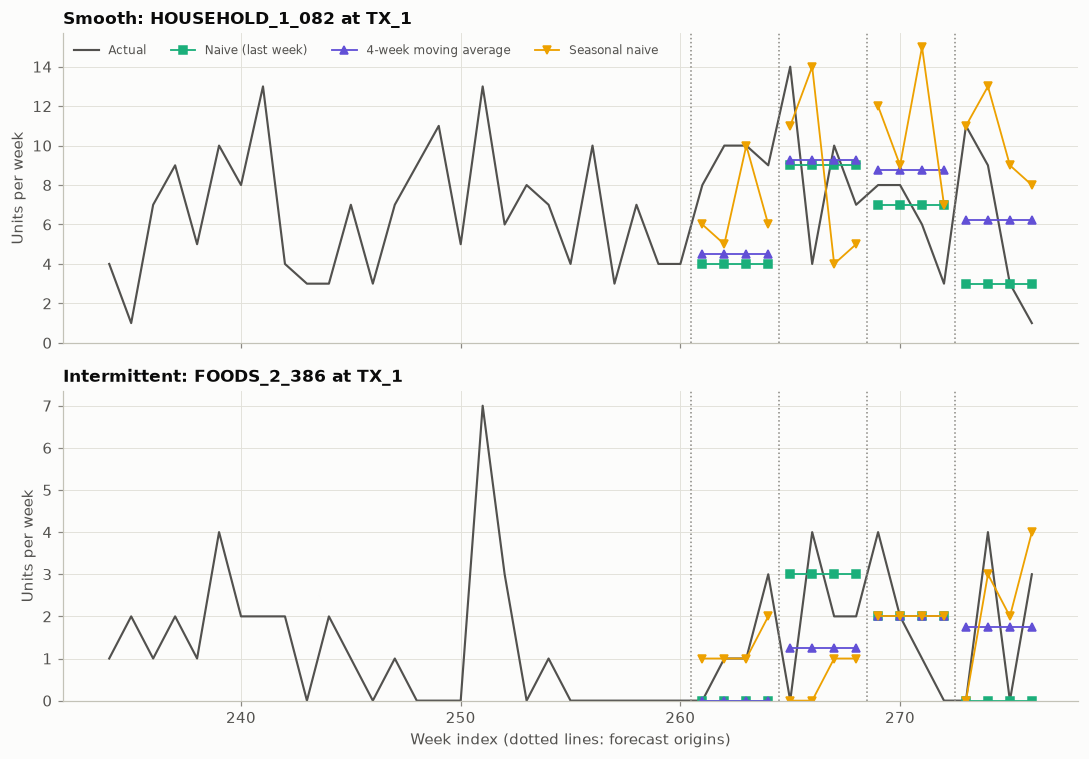

In [6]:
types = fc.drop_duplicates(["item_id", "store_id"]).set_index(["item_id", "store_id"])["demand_type"]
volume = df.groupby(["item_id", "store_id"], observed=True)["sales"].sum()

def median_series(kind):
    v = volume[types[types == kind].index].sort_values()
    return v.index[len(v) // 2]

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
for ax, kind in zip(axes, ["smooth", "intermittent"]):
    item, store = median_series(kind)
    hist = df[(df.item_id == item) & (df.store_id == store) & (df.week_idx >= origins[0] - 26)]
    ax.plot(hist["week_idx"], hist["sales"], color=INK_SECONDARY, linewidth=1.4, label="Actual")
    f = fc[(fc.item_id == item) & (fc.store_id == store)]
    for m in BASELINES:
        for i, o in enumerate(origins):
            seg = f[f.origin_idx == o].sort_values("h")
            ax.plot(seg["target_idx"], seg[m], color=METHOD_COLORS[m], marker=METHOD_MARKERS[m],
                    markersize=5, linewidth=1.2, label=METHOD_LABELS[m] if i == 0 else None)
    for o in origins:
        ax.axvline(o + 0.5, color=MUTED, linestyle=":", linewidth=1)
    ax.set_title(f"{kind.capitalize()}: {item} at {store}", fontsize=11)
    ax.set_ylabel("Units per week")
    ax.set_ylim(bottom=0)
axes[0].legend(loc="upper left", fontsize=8, ncols=4)
axes[1].set_xlabel("Week index (dotted lines: forecast origins)")
plt.tight_layout()
plt.show()

**Reading it:**
- Naive and the moving average draw a flat line for all four target weeks; they can't know what happens after the origin.
- Seasonal naive copies last year's ups and downs. For a single item those peaks rarely land on the same weeks again, which is why it does so badly at item level.
- For the intermittent series every method swings between zero and small numbers, so its week-to-week errors are large relative to its volume. That is the high item-level WAPE in section 2.

## 4. The feature table

The models use one row per series × origin × horizon (one model per horizon, the "direct" strategy). Features fall into four groups:

| Group | Features | Allowed data |
|---|---|---|
| Sales history | lags 1, 2, 4, 8, 13 · rolling mean and std over 4, 8, 13 weeks · zero-sales share over 52 weeks · weeks since listed | sales up to and including the origin |
| Same week last year | sales in week *o + h − 52* | at or before the origin for *h* ≤ 4 |
| Known in advance | price · price vs. its 13-week average · price relative to the department · SNAP days · event days · days open · Christmas flag · week of year · month | the target week (prices never past it) |
| Identifiers | item, department, category, store | — |

**Leakage tests** (`tests/test_features.py`), one per feature:
- Scramble every sale after an origin, rebuild the table, and check that no feature at that origin changed.
- Scramble prices after the target week and check that the price features didn't change.

I also broke the code on purpose twice (lags reaching one week ahead, and a price ratio using next week's price). The tests caught both.

In [7]:
feats = build_features(df)
groups = ({f: "sales history" for f in SALES_FEATURES}
          | {f: "same week last year" for f in HORIZON_SALES_FEATURES}
          | {f: "known in advance" for f in KNOWN_FEATURES}
          | {f: "identifier" for f in ID_FEATURES})

summary = []
for h in (1, 4):
    frame = build_horizon_frame(feats, h)
    test_rows = frame[frame["origin_idx"].isin(origins)]
    summary.append(pd.DataFrame({
        "group": [groups[f] for f in FEATURES],
        f"missing h={h} (all rows)": frame[FEATURES].isna().mean().values,
        f"missing h={h} (backtest rows)": test_rows[FEATURES].isna().mean().values,
    }, index=FEATURES))
summary = pd.concat(summary, axis=1).T.drop_duplicates().T
print(f"Origin-level rows: {len(feats):,} · features per model: {len(FEATURES)}")
summary.style.format({c: "{:.1%}" for c in summary.columns if c.startswith("missing")})

Origin-level rows: 2,046,387 · features per model: 27


,group,missing h=1 (all rows),missing h=1 (backtest rows),missing h=4 (all rows),missing h=4 (backtest rows)
item_id,identifier,0.0%,0.0%,0.0%,0.0%
dept_id,identifier,0.0%,0.0%,0.0%,0.0%
cat_id,identifier,0.0%,0.0%,0.0%,0.0%
store_id,identifier,0.0%,0.0%,0.0%,0.0%
lag_1,sales history,0.0%,0.0%,0.0%,0.0%
lag_2,sales history,0.4%,0.0%,0.5%,0.0%
lag_4,sales history,1.3%,0.0%,1.4%,0.0%
lag_8,sales history,3.1%,0.0%,3.2%,0.0%
lag_13,sales history,5.4%,0.0%,5.5%,0.0%
roll_mean_4,sales history,0.0%,0.0%,0.0%,0.0%


**Reading it:** missing values only come from young series, which don't yet have 13 weeks or a year of history. They are rare in the backtest rows, and both model libraries handle missing values natively, so nothing is filled in.

## 5. What this means for the models

- The bar to clear is the **4-week moving average**, at both levels, on the same four origins and rows.
- All baselines under-forecast (negative bias), consistent with sales growing in 2016. A model that uses recent levels and calendar effects could reduce this.
- The hard part is intermittent and lumpy series. The models get the zero-sales share and rolling statistics so they can tell those series apart.
- If a model beats the baselines by a surprisingly wide margin, the first suspect is leakage (CLAUDE.md rule 8).